Brayden Yow    
9/13/26
Block Checkpoint 1

I chose to simulate a simple system of the arm of a clock swinging in a uniform gravity field. I am moduling a pendulum that has an excapment, this adds energy into the system to counteract any energy loss.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


The movemnt of this pendulum is controled by gravaty and the machanicl componets of the clock. To demonstrate the added energy I will start the simulation at a smaller angel than its equilibrium angle.

In [2]:
# Illustrative physical parameters for a standard grandfather clock
g_val = 9.81  # Acceleration due to gravity (m/s^2)
L = 0.994  # Length of a 'seconds pendulum' (m) (takes ~1 second per single swing)
m = 1.0  # Mass of the pendulum bob (kg)

# Non-conservative mechanics parameters
b_damping = 0.1  # Linear damping coefficient (kg/s)
escapement_kick = 0.08  # Discrete angular velocity boost (rad/s) given by weights

# Initial disturbance conditions
theta0 = np.radians(5.0)  # Initial angular displacement (rad)
omega0 = 0.0  # Initial angular velocity (rad/s), released from rest

# Characteristic scales for physical reference
omega0_small_angle = np.sqrt(g_val / L)  # Natural frequency in small angle limit
T0_small_angle = 2 * np.pi / omega0_small_angle  # Small-angle period (approx. 2.0 seconds)

print(f"Pendulum Length: {L:.3f} m")
print(f"Bob Mass: {m:.1f} kg")
print(f"Small-angle natural period: {T0_small_angle:.4f} s")
print(f"Damping coefficient (b): {b_damping:.2f} kg/s")
print(f"Escapement impulse velocity boost (delta omega): {escapement_kick:.3f} rad/s")


Pendulum Length: 0.994 m
Bob Mass: 1.0 kg
Small-angle natural period: 2.0000 s
Damping coefficient (b): 0.10 kg/s
Escapement impulse velocity boost (delta omega): 0.080 rad/s


In [3]:
def simulate_pendulum_clock(dt=0.001, t_max=40.0):
    """Simulate a mechanical pendulum clock using Euler-Cromer integration.

    Handles continuous non-linear restoring forces, continuous damping, and
    discrete escapement impulses at theta = 0.
    """
    n_steps = int(round(t_max / dt))

    # Initial state initialization
    theta = theta0
    omega = omega0

    # History arrays for analysis
    t_history = [0.0]
    theta_history = [theta]
    omega_history = [omega]

    # Helper function for energy calculation
    def calc_energy(th, om):
        ke = 0.5 * m * (L * om) ** 2
        pe = m * g_val * L * (1.0 - np.cos(th))
        return ke + pe

    E_history = [calc_energy(theta, omega)]

    for step in range(n_steps):
        theta_old = theta

        # Calculate acceleration from the current state
        alpha = -(g_val / L) * np.sin(theta) - (b_damping / m) * omega

        # Euler-Cromer velocity-first update
        omega = omega + alpha * dt
        theta = theta + omega * dt

        # Identify zero-crossing threshold for the escapement kick
        if np.sign(theta) != np.sign(theta_old) and theta_old != 0:
            # Kick is applied in the direction of motion (sign of current velocity)
            omega = omega + escapement_kick * np.sign(omega)

        t = (step + 1) * dt
        energy = calc_energy(theta, omega)

        t_history.append(t)
        theta_history.append(theta)
        omega_history.append(omega)
        E_history.append(energy)

    return (
        np.array(t_history),
        np.array(theta_history),
        np.array(omega_history),
        np.array(E_history),
    )


# Run baseline simulation matching the assignment guidelines
dt_baseline = 0.005
duration = 40.0
t_base, theta_base, omega_base, E_base = simulate_pendulum_clock(
    dt=dt_baseline, t_max=duration
)


I used 40 seconds as a baseline to allow the observation of the system balancing out.

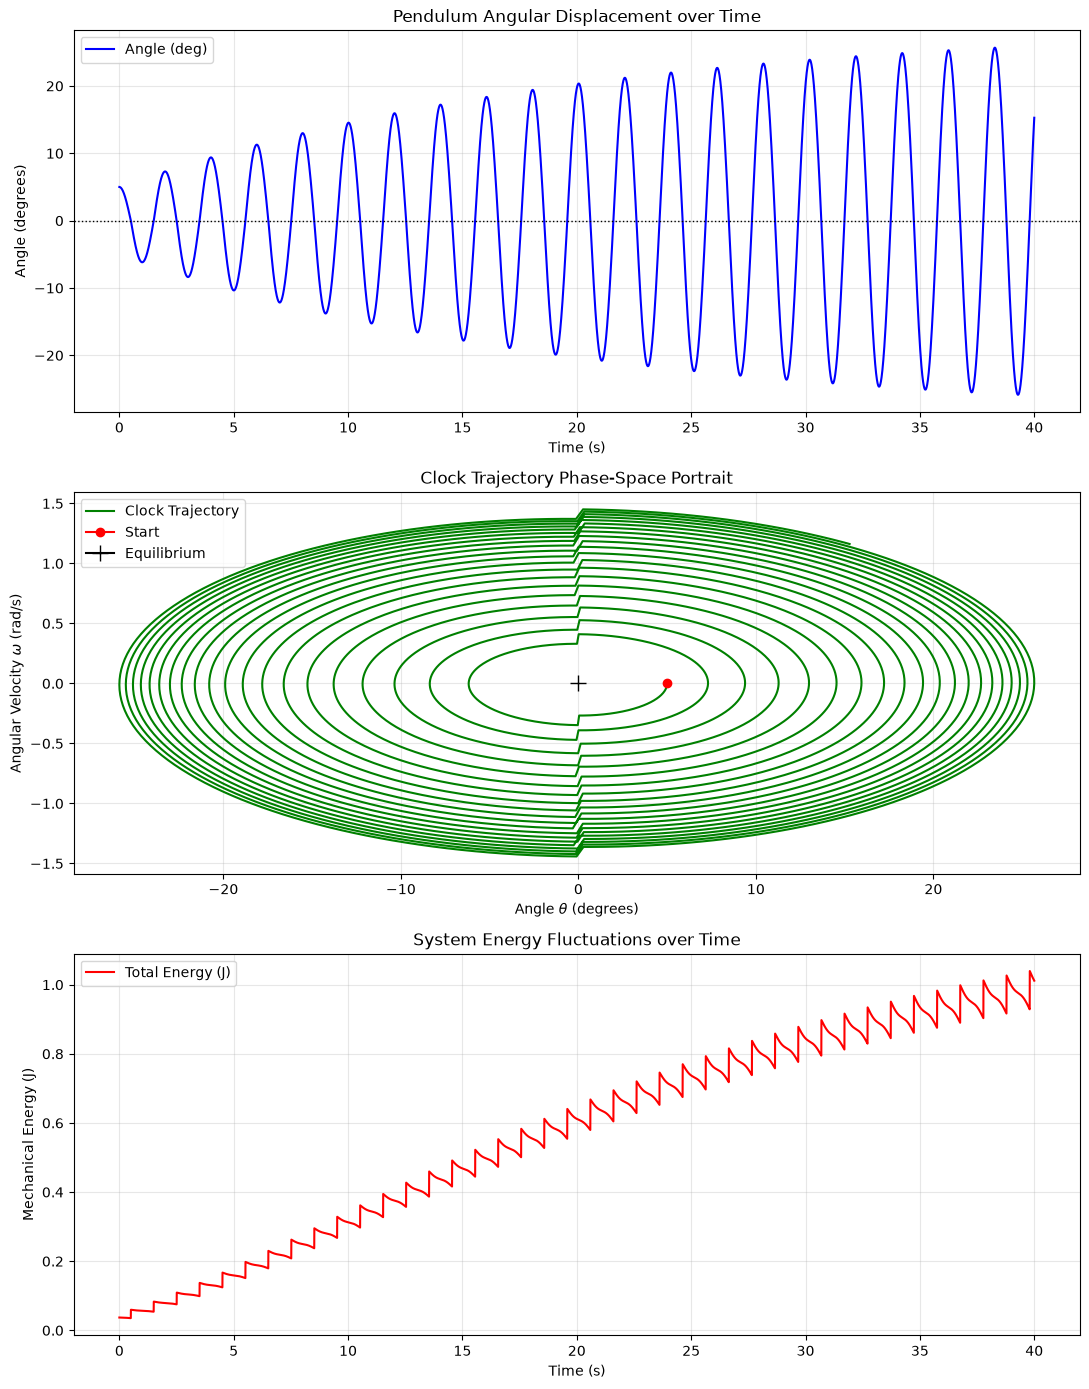

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 14))

# 1. Theta vs Time
axes[0].plot(t_base, np.degrees(theta_base), color="blue", label="Angle (deg)")
axes[0].axhline(y=0.0, color="black", linestyle=":", linewidth=1)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Angle (degrees)")
axes[0].set_title("Pendulum Angular Displacement over Time")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 2. Phase-Space Plot
axes[1].plot(
    np.degrees(theta_base), omega_base, color="green", label="Clock Trajectory"
)
axes[1].plot(np.degrees(theta0), omega0, marker="o", color="red", label="Start")
axes[1].plot(
    0.0, 0.0, marker="+", color="black", markersize=12, label="Equilibrium"
)
axes[1].set_xlabel("Angle $\\theta$ (degrees)")
axes[1].set_ylabel("Angular Velocity $\\omega$ (rad/s)")
axes[1].set_title("Clock Trajectory Phase-Space Portrait")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# 3. Energy vs Time
axes[2].plot(t_base, E_base, color="red", label="Total Energy (J)")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Mechanical Energy (J)")
axes[2].set_title("System Energy Fluctuations over Time")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


Validation 1 — Energy Balance Verification

This being a driven system the energy is not globally conserver, however, if we look to the later cycles we can observer the energy once the system has reached an equilibrium. The energy lost should equal the energy added to the system. This can be found with the change of the system energy over the last 5 seconds, checking if it approaches zero.

In [5]:
# Analyze the energy behavior at the tail end of our run (steady state)
idx_last_5s = np.where(t_base >= (duration - 5.0))[0]
E_steady_state = E_base[idx_last_5s]

delta_E_steady = E_steady_state[-1] - E_steady_state[0]
print(f"Energy net drift over the final 5 seconds: {delta_E_steady:.6f} J")


Energy net drift over the final 5 seconds: 0.076599 J


Validation 2 — Time-Step Convergence Check

A convergence test can be preformed by running the simulation across many progressively smaller timestamps. This proves the model is numerically stable and convergent.

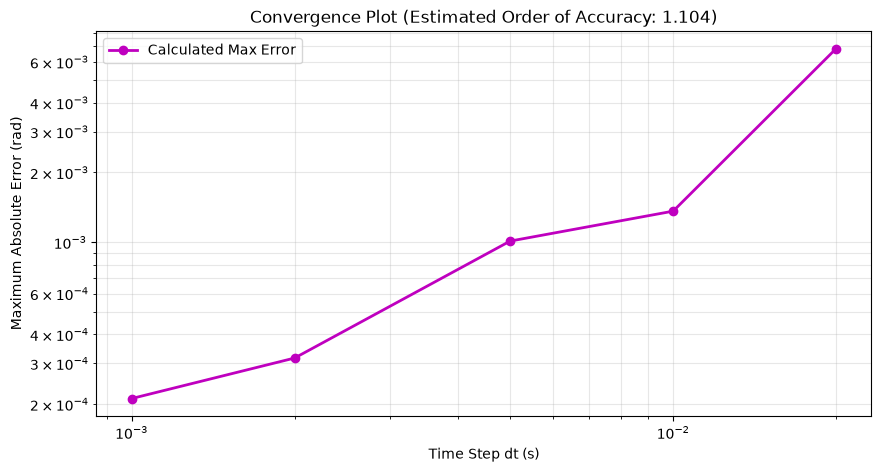

In [6]:
dt_array = np.array([0.02, 0.01, 0.005, 0.002, 0.001])
max_errors = []

# Generate reference solution using an extremely fine timestep
_, theta_ref, _, _ = simulate_pendulum_clock(dt=0.0001, t_max=20.0)

for dt_step in dt_array:
    t_test, theta_test, _, _ = simulate_pendulum_clock(dt=dt_step, t_max=20.0)

    # Subsample the fine reference array to match the timestamps of our test step array
    stride = int(round(dt_step / 0.0001))
    theta_ref_sampled = theta_ref[::stride][: len(theta_test)]

    # Calculate absolute maximum position error
    abs_error = np.max(np.abs(theta_test - theta_ref_sampled[: len(theta_test)]))
    max_errors.append(abs_error)

# Linear regression fit on a log-log scale to find the convergence slope
fit_params = np.polyfit(np.log(dt_array), np.log(max_errors), 1)
order_of_convergence = fit_params[0]

plt.figure(figsize=(10, 5))
plt.loglog(dt_array, max_errors, "mo-", label="Calculated Max Error", linewidth=2)
plt.xlabel("Time Step dt (s)")
plt.ylabel("Maximum Absolute Error (rad)")
plt.title(
    f"Convergence Plot (Estimated Order of Accuracy: {order_of_convergence:.3f})"
)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


Results and Interpretation

I chose to model the mechanical grandfather clock pendulum with the small angle approximating a period of 2 seconds. This is a non linear physical system and was resolved using the Euler Cromer method.
The starting position plot depicts that with a smaller starting position, the displacement being smaller than equilibrium, the continuous addition of velocity provided by the escapement mechanism adds energy into the system from the stored gravitational potential of hanging weights. This fights the damping from the friction until the system stabilizes in its predictable harmonic motion.
The phase space plot is very telling of the physics going on in my system. Instead of spiraling outward endless, a case of no retarding force, or towards the center, a case of only damped motion, there is an equilibrium found at a set distance. This distance is the effect of the clock always going to a set period regardless of its starting angular velocity. If it were to start too fast instead of too slow it would spiral inwards as the retarding force would be grater than the energy added by the escapement.
The validation criteria showed that the mechanical energy was within the limit cycle and the net energy variance approaches 0 J. In addition to the slope of the log log scaling plot being close to 1. These two factor verifies the model converges properly with first oreder accuracy.
